# Bearing Fault Diagnosis from Vibration Signals with a 1D CNN
**Author:** Min Khaung Min Lwin

**Dataset:** Case Western Reserve University (CWRU) Bearing Data Center — 12 kHz drive-end fault data and normal baseline data, https://engineering.case.edu/bearingdatacenter

**Task type:** Image/signal classification with a **Convolutional Neural Network (1D CNN)**: classify raw vibration windows into 4 classes (normal, inner-race fault, ball fault, outer-race fault).



--------

## 1. Data Loading and Inspection

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns, torch
from scipy.io import loadmat
from pathlib import Path

DATA = Path("data/cwru")
device = "cuda" if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu")
print(torch.__version__, device)

2.15.0 mps


In [2]:
manifest = pd.read_csv(DATA / "manifest.csv")
rows = []
for _, r in manifest.iterrows():
    m = loadmat(DATA / r["file"])
    keys = [k for k in m if not k.startswith("__")]
    de = [k for k in keys if k.endswith("DE_time")]
    rpm = [float(m[k].squeeze()) for k in keys if "RPM" in k]
    rows.append({"file": r["file"], "label": r["label"], "size": r["fault_size"], "load": r["load_hp"],
                 "de_keys": de, "n_samples": [m[k].size for k in de], "rpm": rpm})
inspect = pd.DataFrame(rows)
pd.set_option("display.max_colwidth", None)
inspect

,file,label,size,load,de_keys,n_samples,rpm
0,97.mat,normal,0.000,0,[X097_DE_time],[243938],[1796.0]
1,98.mat,normal,0.000,1,[X098_DE_time],[483903],[]
2,99.mat,normal,0.000,2,"[X098_DE_time, X099_DE_time]","[483903, 485063]",[]
3,100.mat,normal,0.000,3,[X100_DE_time],[485643],[1725.0]
4,105.mat,inner_race,0.007,0,[X105_DE_time],[121265],[1797.0]
5,106.mat,inner_race,0.007,1,[X106_DE_time],[121991],[1772.0]
6,107.mat,inner_race,0.007,2,[X107_DE_time],[122136],[1748.0]
7,108.mat,inner_race,0.007,3,[X108_DE_time],[122917],[1721.0]
8,169.mat,inner_race,0.014,0,[X169_DE_time],[121846],[1796.0]
9,170.mat,inner_race,0.014,1,[X170_DE_time],[121846],[1774.0]


#### Step 1: confirm the normal files’ sampling rate

Fault 105 @12 kHz: strongest peak between 5–60 Hz at 60 Hz
Normal 97 assumed 12 kHz: strongest peak between 5–60 Hz at 40 Hz
Normal 97 assumed 48 kHz: strongest peak between 5–60 Hz at 30 Hz


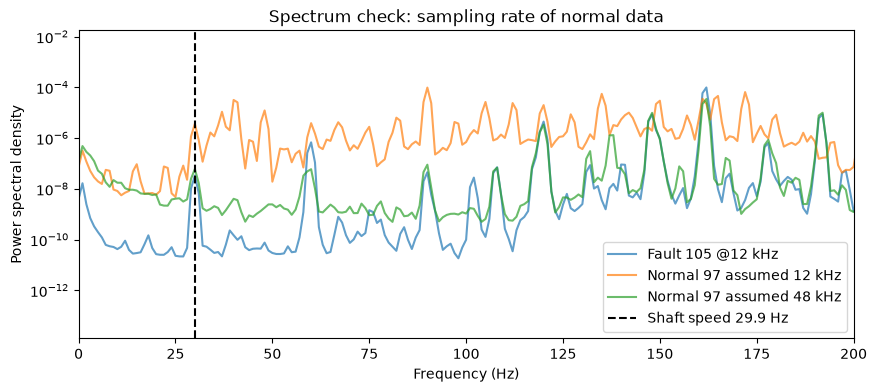

In [3]:
from scipy.signal import welch

def get_de(path):
    """Return the drive-end signal whose number matches the file name (handles files with extra keys)."""
    m = loadmat(path)
    key = f"X{int(Path(path).stem):03d}_DE_time"
    return m[key].squeeze()

x_normal = get_de(DATA / "97.mat")
x_fault = get_de(DATA / "105.mat")      # known 12 kHz, load 0

fig, ax = plt.subplots(figsize=(10, 4))
for x, fs, lab in [(x_fault, 12000, "Fault 105 @12 kHz"),
                   (x_normal, 12000, "Normal 97 assumed 12 kHz"),
                   (x_normal, 48000, "Normal 97 assumed 48 kHz")]:
    f, p = welch(x, fs=fs, nperseg=fs)          # 1 Hz resolution
    band = (f >= 5) & (f <= 60)
    print(f"{lab}: strongest peak between 5–60 Hz at {f[band][np.argmax(p[band])]:.0f} Hz")
    ax.semilogy(f, p, label=lab, alpha=0.7)
ax.axvline(1796 / 60, color="k", linestyle="--", label="Shaft speed 29.9 Hz")
ax.set_xlim(0, 200); ax.set_title("Spectrum check: sampling rate of normal data")
ax.set_xlabel("Frequency (Hz)"); ax.set_ylabel("Power spectral density"); ax.legend()
plt.show()

#### Step 2 (after the check): load, window and split

In [4]:
from scipy.signal import decimate

WIN = 2048            # ≈0.17 s at 12 kHz, about 5 shaft revolutions
CLASSES = ["normal", "inner_race", "ball", "outer_race"]

def load_signal(row, normal_fs=48000):
    """Load the matching DE signal; resample 48 kHz normal data to 12 kHz with an anti-aliasing filter."""
    x = get_de(DATA / row["file"])
    if row["label"] == "normal" and normal_fs == 48000:
        x = decimate(x, 4, zero_phase=True)
    return x.astype(np.float32)

def make_windows(x, stride):
    n = (len(x) - WIN) // stride + 1
    return np.stack([x[i * stride: i * stride + WIN] for i in range(n)])

def build_split(cond, stride):
    """Windows from manifest rows matching `cond` (a boolean mask)."""
    X, y = [], []
    for _, r in manifest[cond].iterrows():
        w = make_windows(load_signal(r), stride)
        X.append(w); y.append(np.full(len(w), CLASSES.index(r["label"])))
    return np.concatenate(X), np.concatenate(y)

m, size, load = manifest, manifest["fault_size"], manifest["load_hp"]
is_normal = m["label"] == "normal"
train_cond = (~is_normal & size.isin([0.007, 0.021]) & load.isin([0, 1, 2])) | (is_normal & load.isin([0, 1]))
val_cond   = (~is_normal & size.isin([0.007, 0.021]) & (load == 3))       | (is_normal & (load == 2))
test_cond  = (~is_normal & (size == 0.014))                                 | (is_normal & (load == 3))

X_train, y_train = build_split(train_cond, stride=512)
X_val, y_val     = build_split(val_cond, stride=WIN)
X_test, y_test   = build_split(test_cond, stride=WIN)
for name, (X, y) in {"train": (X_train, y_train), "val": (X_val, y_val), "test": (X_test, y_test)}.items():
    print(name, X.shape, np.bincount(y, minlength=4))

train (4574, 2048) [ 349 1406 1408 1411]
val (414, 2048) [ 59 119 118 118]
test (767, 2048) [ 59 236 236 236]


#### Step 3: standardise and create the data loaders

In [5]:
from torch.utils.data import TensorDataset, DataLoader

# Standardise with training-set statistics only (no information from val/test)
mu, sigma = X_train.mean(), X_train.std()
def to_tensor(X, y):
    return TensorDataset(torch.tensor((X - mu) / sigma).unsqueeze(1), torch.tensor(y, dtype=torch.long))

train_ds, val_ds, test_ds = to_tensor(X_train, y_train), to_tensor(X_val, y_val), to_tensor(X_test, y_test)
print(train_ds[0][0].shape)   # expect torch.Size([1, 2048]): (channels, length)

torch.Size([1, 2048])


#### for Task 2 representative samples, this cell plots one window from each class

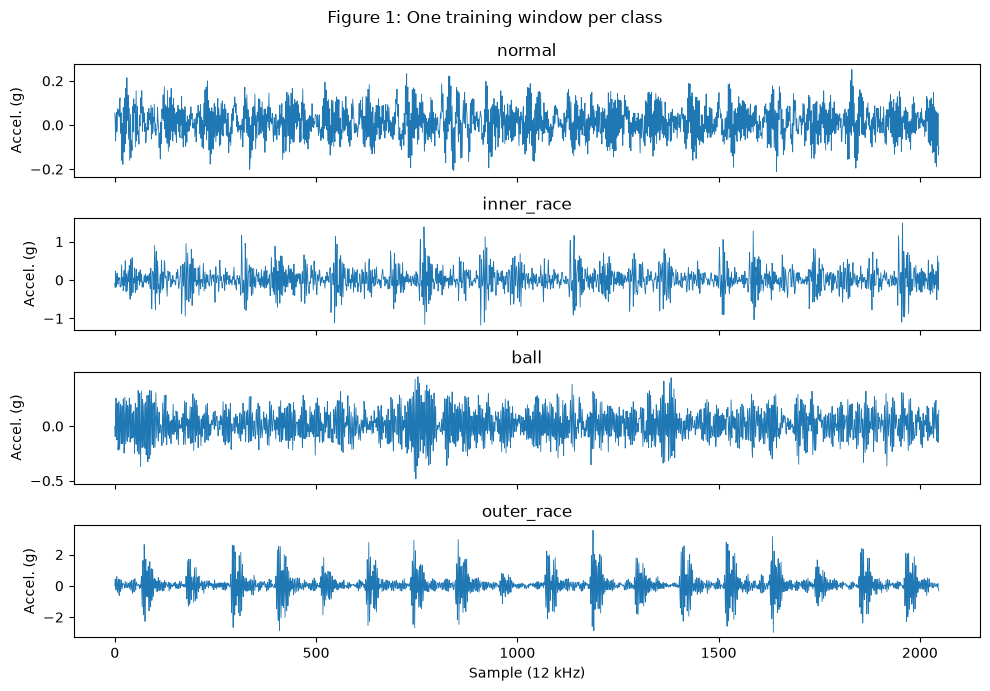

In [6]:
fig, axes = plt.subplots(4, 1, figsize=(10, 7), sharex=True)
for c, ax in enumerate(axes):
    ax.plot(X_train[np.where(y_train == c)[0][0]], lw=0.6)
    ax.set_title(CLASSES[c]); ax.set_ylabel("Accel. (g)")
axes[-1].set_xlabel("Sample (12 kHz)")
plt.suptitle("Figure 1: One training window per class"); plt.tight_layout(); plt.show()

#### Step 4: baseline model and training (Task 3)

In [7]:
import torch.nn as nn
from sklearn.metrics import f1_score

class CNN1D(nn.Module):
    """1D CNN for raw vibration windows. Only `first_kernel` differs between the two experiments."""
    def __init__(self, first_kernel=3, n_classes=4):
        super().__init__()
        def block(cin, cout, k, pool):
            return nn.Sequential(nn.Conv1d(cin, cout, k, padding=k // 2), nn.BatchNorm1d(cout),
                                 nn.ReLU(), nn.MaxPool1d(pool))
        self.features = nn.Sequential(
            block(1, 16, first_kernel, 4),   # 2048 -> 512
            block(16, 32, 3, 4),             # 512  -> 128
            block(32, 64, 3, 4),             # 128  -> 32
            block(64, 64, 3, 2),             # 32   -> 16
        )
        self.head = nn.Sequential(nn.AdaptiveAvgPool1d(1), nn.Flatten(), nn.Dropout(0.3), nn.Linear(64, n_classes))

    def forward(self, x):
        return self.head(self.features(x))

def evaluate(model, ds):
    """Return loss, accuracy, macro-F1 and predictions on a dataset."""
    model.eval(); loader = DataLoader(ds, batch_size=256)
    preds, losses = [], []
    with torch.no_grad():
        for xb, yb in loader:
            out = model(xb.to(device))
            losses.append(nn.functional.cross_entropy(out, yb.to(device), reduction="sum").item())
            preds.append(out.argmax(1).cpu())
    p, y = torch.cat(preds).numpy(), ds.tensors[1].numpy()
    return sum(losses) / len(y), (p == y).mean(), f1_score(y, p, average="macro"), p

def train_model(first_kernel, seed, epochs=30, lr=1e-3, batch=64):
    """Train one configuration; keep the weights from the epoch with the best validation macro-F1."""
    torch.manual_seed(seed); np.random.seed(seed)
    model = CNN1D(first_kernel).to(device)
    counts = np.bincount(y_train, minlength=4)
    weights = torch.tensor(len(y_train) / (4 * counts), dtype=torch.float32, device=device)
    loss_fn = nn.CrossEntropyLoss(weight=weights)          # compensates for fewer normal windows
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    loader = DataLoader(train_ds, batch_size=batch, shuffle=True,
                        generator=torch.Generator().manual_seed(seed))
    hist, best = [], (float("inf"), None)
    for ep in range(epochs):
        model.train(); tot = 0
        for xb, yb in loader:
            opt.zero_grad(); loss = loss_fn(model(xb.to(device)), yb.to(device))
            loss.backward(); opt.step(); tot += loss.item() * len(yb)
        vl, va, vf, _ = evaluate(model, val_ds)
        hist.append({"epoch": ep + 1, "train_loss": tot / len(train_ds), "val_loss": vl, "val_acc": va, "val_f1": vf})
        if vl < best[0]:
            best = (vl, {k: v.detach().clone() for k, v in model.state_dict().items()})
    model.load_state_dict(best[1])
    return model, pd.DataFrame(hist)

baseline, hist_base = train_model(first_kernel=3, seed=0)
print(sum(p.numel() for p in baseline.parameters()), "parameters")
hist_base.tail()

20804 parameters


,epoch,train_loss,val_loss,val_acc,val_f1
25,26,0.000353,0.000262,1.0,1.0
26,27,0.000352,0.000227,1.0,1.0
27,28,0.000319,0.000188,1.0,1.0
28,29,0.000401,0.000283,1.0,1.0
29,30,0.000302,0.000144,1.0,1.0


#### Step 5: the controlled comparison (Task 4)

In [8]:
results, histories, models = [], {}, {}
for k in [3, 64]:
    for seed in [0, 1, 2]:
        model, hist = train_model(first_kernel=k, seed=seed)
        tl, ta, tf, _ = evaluate(model, test_ds)
        results.append({"first_kernel": k, "seed": seed, "test_acc": ta, "test_f1": tf, "test_loss": tl})
        histories[(k, seed)], models[(k, seed)] = hist, model
        print(f"kernel={k} seed={seed}: test acc={ta:.3f}, macro-F1={tf:.3f}")

res = pd.DataFrame(results)
res.groupby("first_kernel")[["test_acc", "test_f1"]].agg(["mean", "std"]).round(3)

kernel=3 seed=0: test acc=0.381, macro-F1=0.294
kernel=3 seed=1: test acc=0.381, macro-F1=0.316
kernel=3 seed=2: test acc=0.382, macro-F1=0.314
kernel=64 seed=0: test acc=0.385, macro-F1=0.375
kernel=64 seed=1: test acc=0.385, macro-F1=0.314
kernel=64 seed=2: test acc=0.385, macro-F1=0.375


test_acc        test_f1       
                 mean    std    mean    std
first_kernel                               
3               0.381  0.001   0.308  0.012
64              0.385  0.000   0.355  0.035

#### Step 6: diagnose the errors (Task 5, plus the “specific model behaviour” requirement)

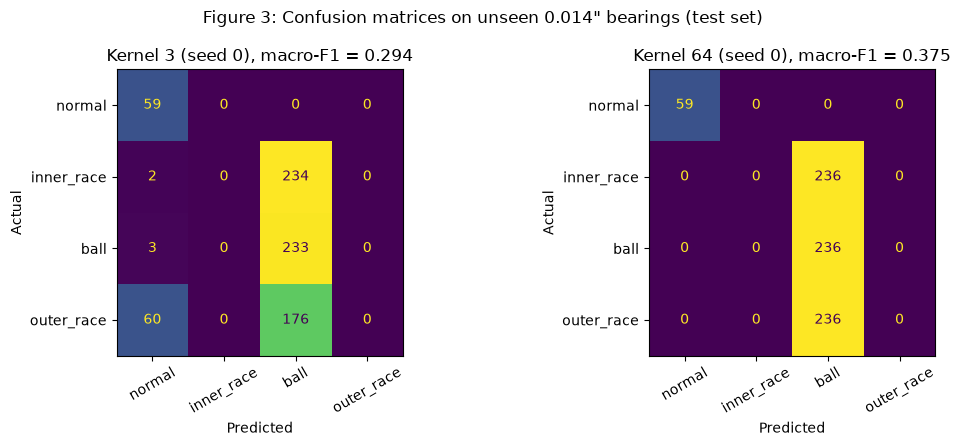

In [9]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, k in zip(axes, [3, 64]):
    _, _, f1, p = evaluate(models[(k, 0)], test_ds)
    ConfusionMatrixDisplay(confusion_matrix(y_test, p), display_labels=CLASSES).plot(
        ax=ax, colorbar=False, xticks_rotation=30)
    ax.set_title(f"Kernel {k} (seed 0), macro-F1 = {f1:.3f}")
    ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
plt.suptitle("Figure 3: Confusion matrices on unseen 0.014\" bearings (test set)")
plt.tight_layout(); plt.savefig("figures/fig3_confusion.png", dpi=150); plt.show()

In [10]:
# Which test files fail? Per-file accuracy and most common prediction (kernel 64, seed 0)
_, _, _, p = evaluate(models[(64, 0)], test_ds)
file_ids = np.concatenate([np.full(len(make_windows(load_signal(r), WIN)), r["file"])
                           for _, r in manifest[test_cond].iterrows()])
per_file = pd.DataFrame({"file": file_ids, "true": [CLASSES[i] for i in y_test],
                         "pred": [CLASSES[i] for i in p]})
per_file.groupby(["file", "true"]).agg(
    acc=("pred", lambda s: (s == per_file.loc[s.index, "true"]).mean()),
    most_common_pred=("pred", lambda s: s.mode()[0])).round(2)

,,acc,most_common_pred
file,true,,
100.mat,normal,1.0,normal
169.mat,inner_race,0.0,ball
170.mat,inner_race,0.0,ball
171.mat,inner_race,0.0,ball
172.mat,inner_race,0.0,ball
185.mat,ball,1.0,ball
186.mat,ball,1.0,ball
187.mat,ball,1.0,ball
188.mat,ball,1.0,ball


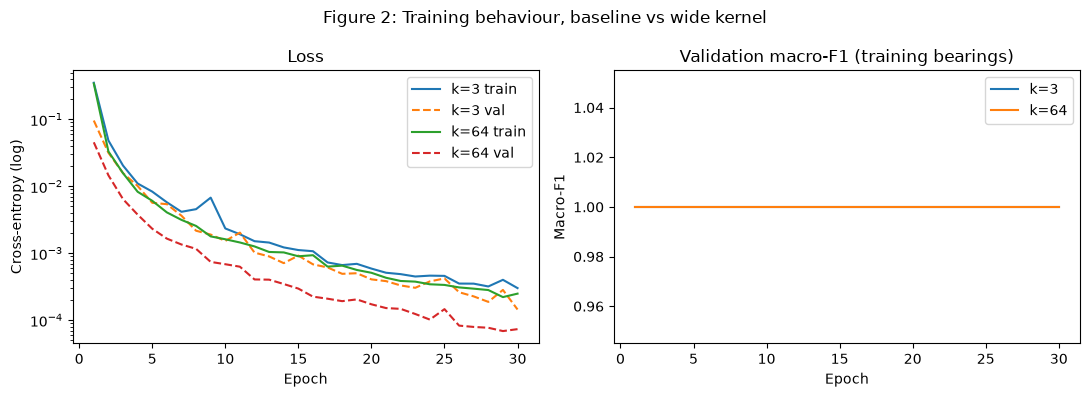

In [11]:
# Figure 2: training curves for both configurations (seed 0)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for k in [3, 64]:
    h = histories[(k, 0)]
    axes[0].plot(h["epoch"], h["train_loss"], label=f"k={k} train")
    axes[0].plot(h["epoch"], h["val_loss"], "--", label=f"k={k} val")
    axes[1].plot(h["epoch"], h["val_f1"], label=f"k={k}")
axes[0].set_yscale("log"); axes[0].set_title("Loss"); axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Cross-entropy (log)")
axes[1].set_title("Validation macro-F1 (training bearings)"); axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Macro-F1")
for ax in axes: ax.legend()
plt.suptitle("Figure 2: Training behaviour, baseline vs wide kernel")
plt.tight_layout(); plt.savefig("figures/fig2_training_curves.png", dpi=150); plt.show()

The confusion matrices show what is going on. On unseen bearings, the model predicts “ball” for almost every faulty window. It gets every normal window right, and nearly every inner-race, ball and outer-race window comes out as “ball”.


| Observation | Evidence |
| :--- | :--- |
| The model collapses to a single fault class | Per-file table: all 12 test fault files have “ball” as their most common prediction. Ball scores 1.0 only because ball is the guess for everything. |
| The wide kernel’s “better” macro-F1 isn’t better fault detection | With kernel 64 (seed 0), 0.375 = (normal 1.0 + ball 0.5 + 0 + 0) ÷ 4. Kernel 3 scores lower only because it also labelled 60 outer-race windows as “normal”. Neither model separates the fault types. |
| Validation was no help | Validation macro-F1 is 1.0 from epoch 1 for both models (Figure 2), even as loss keeps falling. On the training bearings the task is trivially easy. |